# Q10 Practice: Live Readiness Stress Test

Q10 turns the Q9 candidate into a practical-readiness test.

The candidate family is:

- Original three-asset RiskParity core
- BTC SuperTrend satellite with 5%, 7.5%, or 10% cap

The research question is:

> Is the BTC SuperTrend satellite robust enough to move from research to paper trading or small-capital trial, after BTC return haircuts, stricter costs, execution assumptions, and rebalance thresholds?


## 1. Setup and Data Loading

BTC is sampled on the ETF common trading calendar. The candidate remains a satellite, not a fourth core RiskParity asset.


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q10-live-readiness-stress")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CORE_SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
BTC_SYMBOL = "BTC-USD"
ALL_SYMBOLS = CORE_SYMBOLS + (BTC_SYMBOL,)
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
    "BTC-USD": "BTC",
}
START = "2016-06-21"
INITIAL_CAPITAL = 100_000
TRADING_DAYS = 252
REBALANCE_DAYS = 10
VOL_WINDOW = 20
ST_ATR = 10
ST_MULTIPLIER = 3.0
CAPS = [0.05, 0.075, 0.10]
BTC_HAIRCUTS = [1.00, 0.75, 0.50, 0.25, 0.00]
CORE_HAIRCUTS = [1.00, 0.75, 0.50]
REBALANCE_THRESHOLDS = [0.00, 0.01, 0.02]


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol, start=START):
    df = yf.download(symbol, start=start, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["open", "high", "low", "close"])
    df.index = pd.DatetimeIndex(df.index).tz_localize(None).normalize()
    return df

raw = {sym: download_symbol(sym) for sym in ALL_SYMBOLS}
etf_index = raw[CORE_SYMBOLS[0]].index
for sym in CORE_SYMBOLS[1:]:
    etf_index = etf_index.intersection(raw[sym].index)
etf_index = etf_index.sort_values()

data = {}
for sym in CORE_SYMBOLS:
    data[sym] = raw[sym].reindex(etf_index).dropna(subset=["close"])
btc_daily = raw[BTC_SYMBOL].sort_index().ffill()
data[BTC_SYMBOL] = btc_daily.reindex(etf_index, method="ffill").dropna(subset=["close"])

common_index = etf_index
for sym in ALL_SYMBOLS:
    common_index = common_index.intersection(data[sym].index)
common_index = common_index.sort_values()

data = {sym: data[sym].reindex(common_index).copy() for sym in ALL_SYMBOLS}
close = pd.DataFrame({sym: data[sym]["close"] for sym in ALL_SYMBOLS}).dropna()
open_ = pd.DataFrame({sym: data[sym]["open"] for sym in ALL_SYMBOLS}).reindex(close.index)
high = pd.DataFrame({sym: data[sym]["high"] for sym in ALL_SYMBOLS}).reindex(close.index)
low = pd.DataFrame({sym: data[sym]["low"] for sym in ALL_SYMBOLS}).reindex(close.index)
returns_cc_base = close.pct_change().fillna(0.0)
gap_returns_base = (open_ / close.shift(1) - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)
intraday_returns_base = (close / open_ - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)

print(f"共同样本: {close.index[0].date()} 到 {close.index[-1].date()}，{len(close)} 个ETF交易日")
for sym in ALL_SYMBOLS:
    print(f"{SYMBOL_NAMES[sym]}: {close[sym].iloc[-1] / close[sym].iloc[0] - 1:.2%}")


共同样本: 2016-06-21 到 2026-06-23，2426 个ETF交易日
沪深300ETF: 89.15%
纳指100ETF: 603.10%
黄金ETF: 214.79%
BTC: 9280.30%


## 2. Strategy And Backtest Helpers


In [3]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=ST_ATR, multiplier=ST_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr
    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)
    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue
        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]
        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish

btc_st_line, btc_st_signal = supertrend_signal_for_symbol(BTC_SYMBOL, ST_ATR, ST_MULTIPLIER)


In [4]:
def apply_return_haircuts(base_returns, btc_factor=1.0, core_factor=1.0):
    adjusted = base_returns.copy()
    adjusted[list(CORE_SYMBOLS)] = adjusted[list(CORE_SYMBOLS)] * core_factor
    adjusted[BTC_SYMBOL] = adjusted[BTC_SYMBOL] * btc_factor
    return adjusted


def normalize_weights(w):
    weights = {sym: float(max(0.0, w.get(sym, 0.0))) for sym in ALL_SYMBOLS}
    total = sum(weights.values())
    if total > 1.0 + 1e-12:
        weights = {sym: val / total for sym, val in weights.items()}
        total = 1.0
    weights["CASH"] = max(0.0, 1.0 - total)
    return weights


def risk_parity_weight(date, eligible, returns_for_vol, vol_window=VOL_WINDOW):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({})
    hist = returns_for_vol.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({})
    inv = 1.0 / vols
    return normalize_weights((inv / inv.sum()).to_dict())


def build_targets(cap=None, signal=None, returns_for_vol=None, rebalance_threshold=0.0):
    if returns_for_vol is None:
        returns_for_vol = returns_cc_base
    rebalance_mask = pd.Series(False, index=close.index)
    rebalance_mask.iloc[::REBALANCE_DAYS] = True
    rows = []
    last = normalize_weights({})
    for date in close.index:
        if bool(rebalance_mask.loc[date]):
            core = risk_parity_weight(date, CORE_SYMBOLS, returns_for_vol, VOL_WINDOW)
            if cap is None:
                desired = {sym: core.get(sym, 0.0) for sym in CORE_SYMBOLS}
                desired[BTC_SYMBOL] = 0.0
            else:
                desired = {sym: core.get(sym, 0.0) * (1.0 - cap) for sym in CORE_SYMBOLS}
                btc_on = True if signal is None else bool(signal.loc[date])
                desired[BTC_SYMBOL] = cap if btc_on else 0.0
            desired = normalize_weights(desired)
            if rebalance_threshold > 0 and rows:
                last_series = pd.Series(last)
                desired_series = pd.Series(desired)
                max_delta = (desired_series - last_series).abs().max()
                if max_delta >= rebalance_threshold:
                    last = desired
            else:
                last = desired
        rows.append(last)
    targets = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(ALL_SYMBOLS) + ["CASH"]:
        if col not in targets.columns:
            targets[col] = 0.0
    return targets[list(ALL_SYMBOLS) + ["CASH"]]


def backtest_targets(name, targets, returns_cc, gap_returns, intraday_returns, execution="next_close", cost_bps=0.0, fixed_slippage_bps=0.0):
    cost_rate = (cost_bps + fixed_slippage_bps) / 10_000.0
    dates = close.index
    prev_weights = pd.Series(0.0, index=list(ALL_SYMBOLS) + ["CASH"])
    current_weights = prev_weights.copy()
    nav, rets, turnover, costs, held_rows = [], [], [], [], []
    value = INITIAL_CAPITAL
    for i, date in enumerate(dates):
        desired = targets.iloc[i - 1] if i > 0 else prev_weights
        desired = desired.reindex(prev_weights.index).fillna(0.0)
        if execution == "next_close":
            trade = (desired - current_weights).abs().sum() / 2.0
            gross = float((desired[list(ALL_SYMBOLS)] * returns_cc.loc[date, list(ALL_SYMBOLS)]).sum())
            cost = trade * cost_rate
            current_weights = desired.copy()
            day_ret = gross - cost
        elif execution == "next_open":
            gap = float((current_weights[list(ALL_SYMBOLS)] * gap_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            value_after_gap = value * (1.0 + gap)
            trade = (desired - current_weights).abs().sum() / 2.0
            cost_cash = value_after_gap * trade * cost_rate
            value_after_trade = value_after_gap - cost_cash
            intraday = float((desired[list(ALL_SYMBOLS)] * intraday_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            new_value = value_after_trade * (1.0 + intraday)
            day_ret = new_value / value - 1.0 if value > 0 else 0.0
            cost = cost_cash / value if value > 0 else 0.0
            current_weights = desired.copy()
        else:
            raise ValueError(execution)
        value *= (1.0 + day_ret)
        nav.append(value)
        rets.append(day_ret)
        turnover.append(float(trade))
        costs.append(float(cost))
        held_rows.append(current_weights.to_dict())
    return {
        "name": name,
        "nav": pd.Series(nav, index=dates, name=name),
        "returns": pd.Series(rets, index=dates, name=name),
        "targets": targets,
        "weights": pd.DataFrame(held_rows, index=dates).fillna(0.0),
        "turnover": pd.Series(turnover, index=dates, name=name),
        "costs": pd.Series(costs, index=dates, name=name),
    }


def run_strategy(name, cap=None, btc_factor=1.0, core_factor=1.0, execution="next_close", cost_bps=0.0, slippage_bps=0.0, threshold=0.0):
    returns_cc = apply_return_haircuts(returns_cc_base, btc_factor, core_factor)
    gap_returns = apply_return_haircuts(gap_returns_base, btc_factor, core_factor)
    intraday_returns = apply_return_haircuts(intraday_returns_base, btc_factor, core_factor)
    targets = build_targets(cap=cap, signal=btc_st_signal if cap is not None else None, returns_for_vol=returns_cc, rebalance_threshold=threshold)
    return backtest_targets(name, targets, returns_cc, gap_returns, intraday_returns, execution, cost_bps, slippage_bps)


## 3. Metrics


In [5]:
def drawdown(nav_s):
    return nav_s / nav_s.cummax() - 1.0


def max_consecutive(mask):
    longest = current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_returns(nav_s):
    return nav_s.resample("ME").last().pct_change().dropna()


def annual_returns(nav_s):
    year_end = nav_s.resample("YE").last()
    prev = pd.concat([pd.Series([nav_s.iloc[0]], index=[nav_s.index[0]]), year_end])
    out = prev.pct_change().dropna()
    out.index = out.index.year
    return out


def monthly_stats(result):
    months = monthly_returns(result["nav"])
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "月度胜率": len(gains) / len(months) if len(months) else np.nan,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "最差月": months.min() if len(months) else np.nan,
        "最好月": months.max() if len(months) else np.nan,
    }


def underwater_stats(result):
    dd = drawdown(result["nav"]).dropna()
    underwater = dd < 0
    return {
        "水下时间占比": underwater.mean(),
        "平均水下": dd[underwater].mean() if underwater.any() else 0.0,
        "最长水下天数": max_consecutive(underwater),
        "超过-10%天数": int((dd <= -0.10).sum()),
        "当前水下深度": float(dd.iloc[-1]),
    }


def drawdown_events(result):
    dd = drawdown(result["nav"]).dropna()
    events = []
    in_dd = False
    start = trough = None
    trough_value = 0.0
    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                events.append({"开始日期": start, "最低点日期": trough, "恢复日期": date, "深度": trough_value, "恢复天数": (date - trough).days, "总持续天数": (date - start).days})
                in_dd = False
    if in_dd and start is not None:
        last = dd.index[-1]
        events.append({"开始日期": start, "最低点日期": trough, "恢复日期": pd.NaT, "深度": trough_value, "恢复天数": np.nan, "总持续天数": (last - start).days})
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def recovery_stats(result):
    events = drawdown_events(result)
    if events.empty:
        return {"平均修复天数": np.nan, "最长修复天数": np.nan, "未修复回撤深度": 0.0}
    recovered = events.dropna(subset=["恢复天数"])
    unresolved = events[events["恢复天数"].isna()]
    return {
        "平均修复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "最长修复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "未修复回撤深度": unresolved.iloc[-1]["深度"] if len(unresolved) else 0.0,
    }


def strategy_metrics(result):
    nav = result["nav"].dropna()
    ret = result["returns"].reindex(nav.index).fillna(0.0)
    total = nav.iloc[-1] / nav.iloc[0] - 1.0
    annual = (nav.iloc[-1] / nav.iloc[0]) ** (TRADING_DAYS / (len(nav) - 1)) - 1.0
    vol = ret.std(ddof=1) * np.sqrt(TRADING_DAYS)
    max_dd = drawdown(nav).min()
    sharpe = (ret.mean() * TRADING_DAYS) / vol if vol > 0 else np.nan
    calmar = annual / abs(max_dd) if max_dd < 0 else np.nan
    downside = ret[ret < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = (ret.mean() * TRADING_DAYS) / downside_dev if downside_dev and downside_dev > 0 else np.nan
    weights = result["weights"].reindex(nav.index).fillna(0.0)
    row = {
        "累计收益": total,
        "年化收益": annual,
        "年化波动": vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
        "年化换手": result["turnover"].mean() * TRADING_DAYS,
        "成本拖累": result["costs"].sum(),
        "平均BTC权重": weights[BTC_SYMBOL].mean(),
        "当前BTC权重": weights[BTC_SYMBOL].iloc[-1],
        "平均现金": weights["CASH"].mean(),
    }
    row.update(monthly_stats(result))
    row.update(underwater_stats(result))
    row.update(recovery_stats(result))
    row["最差年"] = annual_returns(nav).min()
    return row


## 4. Baseline Live-Readiness Variants


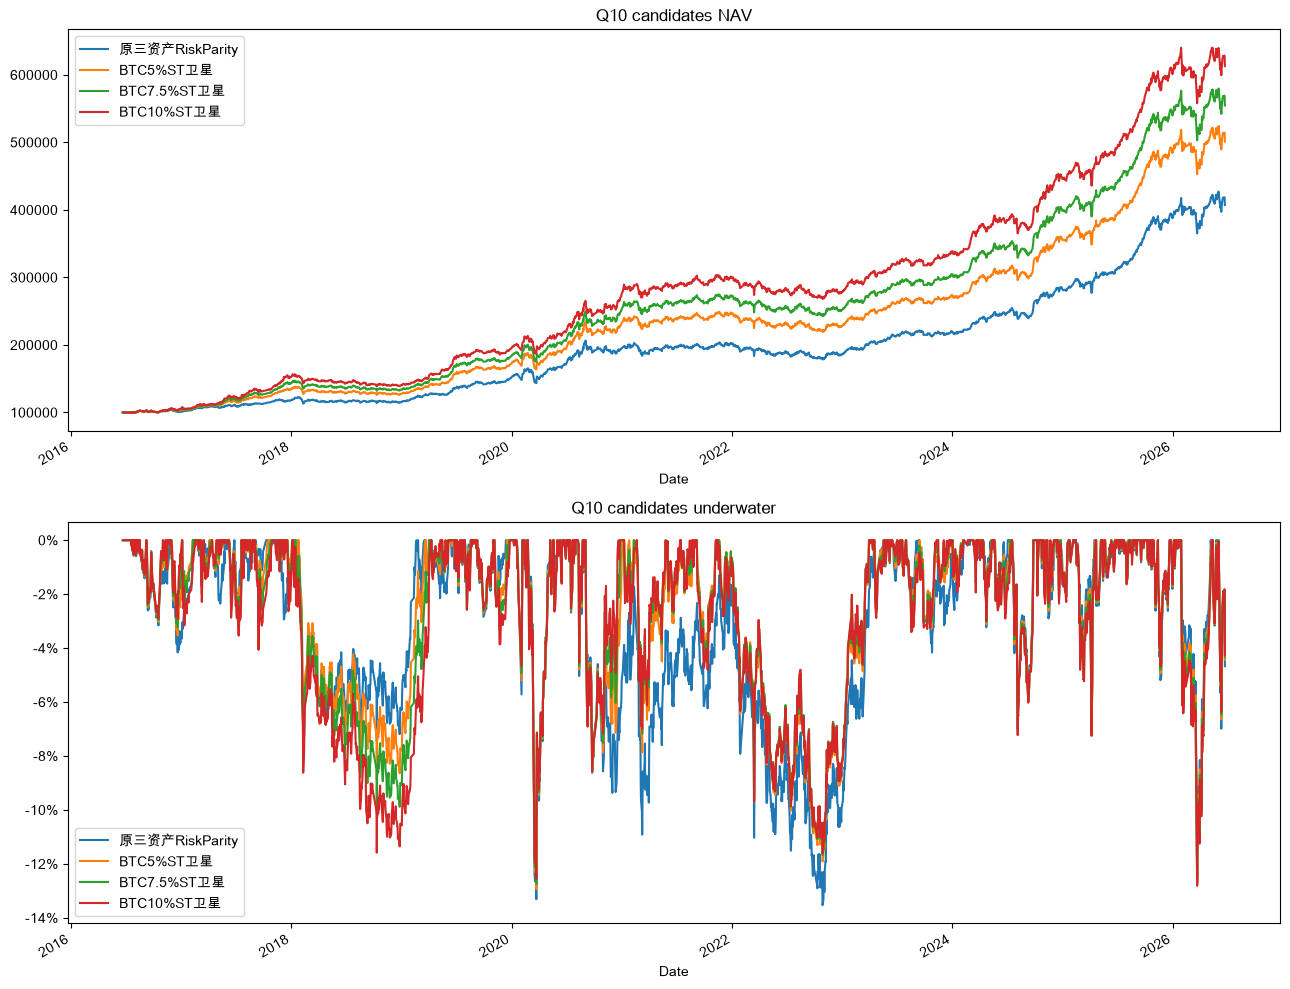

,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,年化换手,成本拖累,平均BTC权重,...,最好月,水下时间占比,平均水下,最长水下天数,超过-10%天数,当前水下深度,平均修复天数,最长修复天数,未修复回撤深度,最差年
原三资产RiskParity,3.0715,0.1571,0.1122,-0.1353,1.3561,1.1609,1.2769,1.9813,0.0,0.0000,...,0.0922,0.8487,-0.0365,653.0,83.0,-0.0467,12.4044,376.0,-0.0699,-0.0819
BTC5%ST卫星,4.0110,0.1823,0.1095,-0.1293,1.5840,1.4096,1.5052,2.2069,0.0,0.0272,...,0.0979,0.8289,-0.0318,332.0,42.0,-0.0443,10.6289,161.0,-0.0665,-0.0784
BTC7.5%ST卫星,4.5463,0.1949,0.1103,-0.1275,1.6687,1.5288,1.6007,2.3196,0.0,0.0408,...,0.1016,0.8310,-0.0327,330.0,39.0,-0.0432,10.3988,173.0,-0.0648,-0.0767
BTC10%ST卫星,5.1293,0.2073,0.1126,-0.1281,1.7299,1.6179,1.6712,2.4324,0.0,0.0544,...,0.1105,0.8339,-0.0348,334.0,89.0,-0.0425,11.1299,179.0,-0.0636,-0.0788


In [6]:
base_results = {
    "原三资产RiskParity": run_strategy("原三资产RiskParity", cap=None),
    "BTC5%ST卫星": run_strategy("BTC5%ST卫星", cap=0.05),
    "BTC7.5%ST卫星": run_strategy("BTC7.5%ST卫星", cap=0.075),
    "BTC10%ST卫星": run_strategy("BTC10%ST卫星", cap=0.10),
}
base_metrics = pd.DataFrame({name: strategy_metrics(result) for name, result in base_results.items()}).T
base_metrics.to_csv(OUTPUT_DIR / "base_candidate_metrics.csv", encoding="utf-8-sig")

nav_base = pd.DataFrame({name: result["nav"] for name, result in base_results.items()})
nav_base.to_csv(OUTPUT_DIR / "base_candidate_nav.csv", encoding="utf-8-sig")
underwater_base = nav_base.apply(drawdown)
underwater_base.to_csv(OUTPUT_DIR / "base_candidate_underwater.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
nav_base.plot(ax=axes[0])
axes[0].set_title("Q10 candidates NAV")
underwater_base.plot(ax=axes[1])
axes[1].set_title("Q10 candidates underwater")
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "base_candidates_nav_underwater.png", dpi=160)
plt.show()

base_metrics.round(4)


## 5. BTC Return Haircut Stress


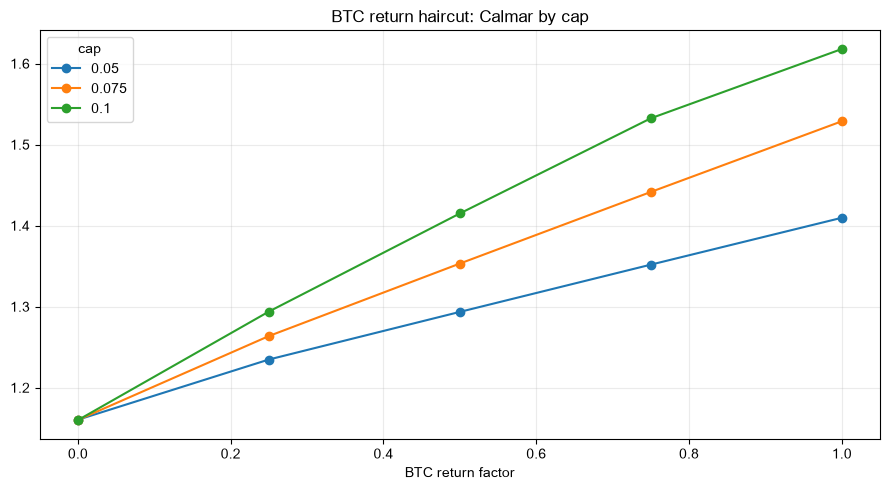

,cap,btc_return_factor,年化收益,最大回撤,夏普,卡玛,水下时间占比,最长水下天数,超过-10%天数,通过实盘门槛
0,0.050,1.00,0.1823,-0.1293,1.5840,1.4096,0.8289,332,42,True
1,0.075,1.00,0.1949,-0.1275,1.6687,1.5288,0.8310,330,39,True
2,0.100,1.00,0.2073,-0.1281,1.7299,1.6179,0.8339,334,89,True
3,0.050,0.75,0.1740,-0.1287,1.5355,1.3518,0.8298,332,41,True
4,0.075,0.75,0.1823,-0.1265,1.6112,1.4415,0.8310,332,35,True
5,0.100,0.75,0.1907,-0.1244,1.6743,1.5324,0.8310,330,32,True
6,0.050,0.50,0.1656,-0.1281,1.4812,1.2935,0.8359,332,41,True
7,0.075,0.50,0.1699,-0.1255,1.5397,1.3532,0.8293,332,35,True
8,0.100,0.50,0.1740,-0.1230,1.5940,1.4150,0.8302,332,31,True
9,0.050,0.25,0.1573,-0.1274,1.4212,1.2347,0.8434,332,38,True


In [7]:
haircut_rows = []
for btc_factor in BTC_HAIRCUTS:
    rp = run_strategy("原三资产RiskParity", cap=None, btc_factor=btc_factor)
    rp_m = strategy_metrics(rp)
    for cap in CAPS:
        name = f"BTC{cap:.1%}ST卫星_BTC收益{btc_factor:.0%}"
        result = run_strategy(name, cap=cap, btc_factor=btc_factor)
        row = strategy_metrics(result)
        row["cap"] = cap
        row["btc_return_factor"] = btc_factor
        row["策略"] = name
        row["年化收益差_vs_RP"] = row["年化收益"] - rp_m["年化收益"]
        row["卡玛差_vs_RP"] = row["卡玛"] - rp_m["卡玛"]
        row["最大回撤差_vs_RP"] = row["最大回撤"] - rp_m["最大回撤"]
        row["通过实盘门槛"] = row["年化收益"] > rp_m["年化收益"] and row["卡玛"] >= rp_m["卡玛"] and row["最大回撤"] >= rp_m["最大回撤"]
        haircut_rows.append(row)
haircut_table = pd.DataFrame(haircut_rows)
haircut_table.to_csv(OUTPUT_DIR / "btc_return_haircut_stress.csv", encoding="utf-8-sig", index=False)

pivot = haircut_table.pivot(index="btc_return_factor", columns="cap", values="卡玛")
fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot(marker="o", ax=ax)
ax.set_title("BTC return haircut: Calmar by cap")
ax.set_xlabel("BTC return factor")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "btc_return_haircut_calmar.png", dpi=160)
plt.show()

haircut_table[["cap", "btc_return_factor", "年化收益", "最大回撤", "夏普", "卡玛", "水下时间占比", "最长水下天数", "超过-10%天数", "通过实盘门槛"]].round(4)


## 6. Core Asset Return Haircut Stress


In [8]:
core_rows = []
for core_factor in CORE_HAIRCUTS:
    rp = run_strategy("原三资产RiskParity", cap=None, core_factor=core_factor)
    rp_m = strategy_metrics(rp)
    for cap in CAPS:
        result = run_strategy(f"BTC{cap:.1%}ST卫星_core{core_factor:.0%}", cap=cap, core_factor=core_factor)
        row = strategy_metrics(result)
        row["cap"] = cap
        row["core_return_factor"] = core_factor
        row["年化收益差_vs_RP"] = row["年化收益"] - rp_m["年化收益"]
        row["卡玛差_vs_RP"] = row["卡玛"] - rp_m["卡玛"]
        row["通过实盘门槛"] = row["年化收益"] > rp_m["年化收益"] and row["卡玛"] >= rp_m["卡玛"] and row["最大回撤"] >= rp_m["最大回撤"]
        core_rows.append(row)
core_haircut_table = pd.DataFrame(core_rows)
core_haircut_table.to_csv(OUTPUT_DIR / "core_return_haircut_stress.csv", encoding="utf-8-sig", index=False)
core_haircut_table[["cap", "core_return_factor", "年化收益", "最大回撤", "夏普", "卡玛", "通过实盘门槛"]].round(4)


,cap,core_return_factor,年化收益,最大回撤,夏普,卡玛,通过实盘门槛
0,0.050,1.00,0.1823,-0.1293,1.5840,1.4096,True
1,0.075,1.00,0.1949,-0.1275,1.6687,1.5288,True
2,0.100,1.00,0.2073,-0.1281,1.7299,1.6179,True
3,0.050,0.75,0.1432,-0.0989,1.6395,1.4476,True
4,0.075,0.75,0.1563,-0.0994,1.7250,1.5716,True
5,0.100,0.75,0.1693,-0.1065,1.7722,1.5900,False
6,0.050,0.50,0.1046,-0.0686,1.7201,1.5251,False
7,0.075,0.50,0.1182,-0.0788,1.7805,1.4989,False
8,0.100,0.50,0.1318,-0.0973,1.7842,1.3544,False


## 7. Cost, Slippage, Execution, And Rebalance Threshold Stress


In [9]:
implementation_rows = []
for execution in ["next_close", "next_open"]:
    for cost_bps in [10, 20, 50]:
        for slippage_bps in [0, 10, 25]:
            for threshold in REBALANCE_THRESHOLDS:
                rp = run_strategy("原三资产RiskParity", cap=None, execution=execution, cost_bps=cost_bps, slippage_bps=slippage_bps, threshold=threshold)
                rp_m = strategy_metrics(rp)
                for cap in CAPS:
                    result = run_strategy(f"BTC{cap:.1%}ST卫星", cap=cap, execution=execution, cost_bps=cost_bps, slippage_bps=slippage_bps, threshold=threshold)
                    row = strategy_metrics(result)
                    row["cap"] = cap
                    row["execution"] = execution
                    row["cost_bps"] = cost_bps
                    row["slippage_bps"] = slippage_bps
                    row["rebalance_threshold"] = threshold
                    row["年化收益差_vs_RP"] = row["年化收益"] - rp_m["年化收益"]
                    row["卡玛差_vs_RP"] = row["卡玛"] - rp_m["卡玛"]
                    row["最大回撤差_vs_RP"] = row["最大回撤"] - rp_m["最大回撤"]
                    row["通过实盘门槛"] = row["年化收益"] > rp_m["年化收益"] and row["卡玛"] >= rp_m["卡玛"] and row["最大回撤"] >= rp_m["最大回撤"]
                    implementation_rows.append(row)
implementation_table = pd.DataFrame(implementation_rows)
implementation_table.to_csv(OUTPUT_DIR / "implementation_stress_grid.csv", encoding="utf-8-sig", index=False)
implementation_summary = implementation_table.groupby("cap").agg(
    场景数=("通过实盘门槛", "count"),
    通过数=("通过实盘门槛", "sum"),
    平均年化收益=("年化收益", "mean"),
    最低年化收益=("年化收益", "min"),
    平均卡玛=("卡玛", "mean"),
    最低卡玛=("卡玛", "min"),
    平均最大回撤=("最大回撤", "mean"),
    最高年化换手=("年化换手", "max"),
).reset_index()
implementation_summary["通过率"] = implementation_summary["通过数"] / implementation_summary["场景数"]
implementation_summary.to_csv(OUTPUT_DIR / "implementation_stress_summary.csv", encoding="utf-8-sig", index=False)
implementation_summary.round(4)


,cap,场景数,通过数,平均年化收益,最低年化收益,平均卡玛,最低卡玛,平均最大回撤,最高年化换手,通过率
0,0.050,54,54,0.1723,0.1628,1.3364,1.2403,-0.1290,2.2069,1.0
1,0.075,54,54,0.1841,0.1739,1.4359,1.3440,-0.1282,2.3196,1.0
2,0.100,54,54,0.1959,0.1849,1.5150,1.3848,-0.1293,2.4324,1.0


## 8. Current Signal And Paper Trading Rule Draft


In [10]:
latest_date = close.index[-1]
latest_signal = bool(btc_st_signal.loc[latest_date])
latest_line = float(btc_st_line.loc[latest_date]) if not pd.isna(btc_st_line.loc[latest_date]) else np.nan
latest_btc_close = float(close.loc[latest_date, BTC_SYMBOL])
latest_targets = {}
for cap in CAPS:
    targets = build_targets(cap=cap, signal=btc_st_signal, returns_for_vol=returns_cc_base, rebalance_threshold=0.0)
    latest_targets[f"BTC{cap:.1%}ST卫星"] = targets.iloc[-1]
latest_targets_df = pd.DataFrame(latest_targets).T
latest_targets_df.to_csv(OUTPUT_DIR / "latest_target_weights.csv", encoding="utf-8-sig")

paper_rule = pd.DataFrame([
    {"项目": "候选策略", "规则": "原三资产 RiskParity 核心 + BTC SuperTrend 卫星"},
    {"项目": "优先纸面跟踪 cap", "规则": "5% 和 7.5%；10% 作为进攻候选继续观察"},
    {"项目": "调仓频率", "规则": "每 10 个 ETF 交易日检查一次"},
    {"项目": "BTC 开关", "规则": "BTC close > SuperTrend line 时卫星开启，否则卫星仓位进入现金"},
    {"项目": "执行假设", "规则": "信号日收盘后计算，下一交易日执行；纸面记录 next-open 与 next-close 两套价格"},
    {"项目": "调仓阈值", "规则": "目标权重变化小于 1% 可不交易；BTC 开关变化必须记录"},
    {"项目": "成本记录", "规则": "至少记录 20 bps 成本 + 10 bps 滑点压力版本"},
    {"项目": "暂停条件", "规则": "策略相对原 RP 的最大回撤优势连续 3 个月消失，或 BTC 卫星触发超过预设亏损阈值时暂停复核"},
    {"项目": "纸面跟踪期", "规则": "至少 3 个月，覆盖不少于 6 次调仓检查"},
])
paper_rule.to_csv(OUTPUT_DIR / "paper_trading_rule_draft.csv", encoding="utf-8-sig", index=False)

signal_summary = pd.Series({
    "latest_date": str(latest_date.date()),
    "btc_close": latest_btc_close,
    "btc_supertrend_line": latest_line,
    "btc_supertrend_on": latest_signal,
})
signal_summary.to_csv(OUTPUT_DIR / "latest_signal_summary.csv", encoding="utf-8-sig")
print(signal_summary)
latest_targets_df.round(4)


latest_date              2026-06-23
btc_close               62533.96875
btc_supertrend_line    70231.491797
btc_supertrend_on             False
dtype: object


,510300.SS,513100.SS,518880.SS,BTC-USD,CASH
BTC5.0%ST卫星,0.4365,0.2080,0.3055,0.0,0.050
BTC7.5%ST卫星,0.4250,0.2025,0.2975,0.0,0.075
BTC10.0%ST卫星,0.4135,0.1970,0.2895,0.0,0.100


## 9. Decision Summary


In [11]:
summary = pd.Series({
    "sample_start": str(close.index[0].date()),
    "sample_end": str(close.index[-1].date()),
    "base_candidate": "BTC10%ST卫星",
    "paper_tracking_recommendation": "yes",
    "small_capital_trial_recommendation": "not_yet_before_paper_tracking",
    "preferred_paper_caps": "5%, 7.5%",
    "growth_candidate_cap": "10%",
    "btc_50pct_haircut_10pct_pass": bool(haircut_table[(haircut_table["cap"] == 0.10) & (haircut_table["btc_return_factor"] == 0.50)]["通过实盘门槛"].iloc[0]),
    "implementation_pass_rate_5pct": float(implementation_summary[implementation_summary["cap"] == 0.05]["通过率"].iloc[0]),
    "implementation_pass_rate_7_5pct": float(implementation_summary[implementation_summary["cap"] == 0.075]["通过率"].iloc[0]),
    "implementation_pass_rate_10pct": float(implementation_summary[implementation_summary["cap"] == 0.10]["通过率"].iloc[0]),
    "latest_btc_supertrend_on": latest_signal,
})
summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")
summary


sample_start                                             2016-06-21
sample_end                                               2026-06-23
base_candidate                                           BTC10%ST卫星
paper_tracking_recommendation                                   yes
small_capital_trial_recommendation    not_yet_before_paper_tracking
preferred_paper_caps                                       5%, 7.5%
growth_candidate_cap                                            10%
btc_50pct_haircut_10pct_pass                                   True
implementation_pass_rate_5pct                                   1.0
implementation_pass_rate_7_5pct                                 1.0
implementation_pass_rate_10pct                                  1.0
latest_btc_supertrend_on                                      False
dtype: object

### Conclusion Template

- Historical best:
- Stress-test winner:
- Paper-trading candidate:
- Small-capital readiness:
- Main implementation risk:
- What to track next:
